<a href="https://www.kaggle.com/code/emon818/dti-mri-quality-control-with-attention-mechanism?scriptVersionId=372560486" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Automated 3D MRI/DTI Quality Control Pipeline (Leak-Free, Shortcut-Free, Dual-T4 GPU)

### What This Notebook Fixes Compared to V2
1. **Eliminates the Background-Noise Shortcut (Steps 2 & 10):**
   - All synthetic artifacts (`motion`, `ghost`, `noise`, `slice_dropout`, `combined`) are applied **strictly inside the brain mask** (`mask = volume > 0`), and the background is re-zeroed afterward.
   - Both **Good** and **Poor** volumes receive realistic baseline scanner Rician noise (`snr_scale ~ U(0.008, 0.018)`) inside the brain mask, and `motion` / `ghost` / `slice_dropout` no longer inject extra Rician noise.
   - A dedicated **Step 3 Shortcut Audit** trains a simple Logistic Regression on background/intensity summary stats to verify that trivial shortcuts do not solve the task.
2. **Eliminates Test-Set Checkpoint Leakage (Steps 5, 6 & 7):**
   - Uses a strict **3-way subject-wise split (`60% Train / 20% Validation / 20% Test`)** via `GroupShuffleSplit` with zero subject overlap across all three partitions.
   - Model checkpoints are selected **exclusively on `val_loader`**; `test_loader` is touched **once** after training finishes.
3. **Eliminates 5-Fold Cross-Validation Pretraining Leakage (Step 8):**
   - `DTI_CNN1` and `DTI_CNN2` are pre-trained **from scratch inside every fold** using only that fold's training subjects—never reusing global pretrained weights.
4. **Optimized for Kaggle 2× NVIDIA T4 GPUs:**
   - Automatic `nn.DataParallel` wrapping across both GPUs, mixed precision (`torch.amp.autocast('cuda')` + `GradScaler`), `pin_memory=True`, and clean `unwrap_model()` helpers so checkpoints and 3D Grad-CAM hooks work without `DataParallel` errors.


## Step 1: Dual-T4 GPU Setup, Global Config & Dataset Discovery


In [1]:
import os
import glob
import random
import numpy as np
import torch

SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# Hardware & 2x T4 Configuration
GPU_COUNT = torch.cuda.device_count()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

# Scale cohort up to 150 subjects (300 volumes: 180 train / 60 val / 60 test) if available
MAX_SUBJECTS = 150
BATCH_SIZE = 8 if GPU_COUNT >= 2 else 4   # 4 volumes per T4 GPU
NUM_WORKERS = 2
NUM_EPOCHS = 20

print(f"Device: {DEVICE} | GPUs Detected: {GPU_COUNT} | AMP Enabled: {USE_AMP}")
for i in range(GPU_COUNT):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {props.name} ({props.total_memory / (1024**3):.1f} GB VRAM)")

def wrap_model(model):
    model = model.to(DEVICE)
    if GPU_COUNT > 1:
        model = torch.nn.DataParallel(model)
    return model

def unwrap_model(model):
    return model.module if isinstance(model, torch.nn.DataParallel) else model

# Discover BraTS / NIfTI input files
input_dirs = glob.glob("/kaggle/input/*")
print("\nInput directories found:")
for d in input_dirs:
    print(" -", d)

all_scans = sorted(glob.glob("/kaggle/input/**/*flair*.nii*", recursive=True))
if not all_scans:
    all_scans = [
        f for f in sorted(glob.glob("/kaggle/input/**/*.nii*", recursive=True))
        if "seg" not in os.path.basename(f).lower()
    ]

print(f"\nTotal eligible NIfTI volumes found: {len(all_scans)}")
for f in all_scans[:5]:
    print(" ", f)


Device: cuda | GPUs Detected: 2 | AMP Enabled: True
  GPU 0: Tesla T4 (14.6 GB VRAM)
  GPU 1: Tesla T4 (14.6 GB VRAM)

Input directories found:
 - /kaggle/input/notebooks

Total eligible NIfTI volumes found: 953
  /kaggle/input/notebooks/victorfernandezalbor/brats2021-u-net-segmentation-model-300-1251-img/data/BraTS2021_00495_flair.nii.gz
  /kaggle/input/notebooks/victorfernandezalbor/brats2021-u-net-segmentation-model-300-1251-img/data/BraTS2021_00621_flair.nii.gz
  /kaggle/input/notebooks/victorfernandezalbor/brats2021-u-net-segmentation-model-300-1251-img/post_process_data/00000/BraTS2021_00000_flair.nii.gz
  /kaggle/input/notebooks/victorfernandezalbor/brats2021-u-net-segmentation-model-300-1251-img/post_process_data/00002/BraTS2021_00002_flair.nii.gz
  /kaggle/input/notebooks/victorfernandezalbor/brats2021-u-net-segmentation-model-300-1251-img/post_process_data/00005/BraTS2021_00005_flair.nii.gz


In [2]:
# Keep only post_process_data scans and deduplicate by BraTS subject ID
all_scans = sorted(glob.glob("/kaggle/input/**/post_process_data/**/*flair*.nii*", recursive=True))
seen_ids, unique_scans = set(), []
for f in all_scans:
    sid = os.path.basename(f).split("_flair")[0]
    if sid not in seen_ids:
        seen_ids.add(sid)
        unique_scans.append(f)
all_scans = unique_scans
print(f"Unique post_process_data FLAIR subjects ready: {len(all_scans)}")

Unique post_process_data FLAIR subjects ready: 951


## Step 2: Shortcut-Free Brain-Masked Artifact Simulation & Strict 3-Way Subject Split
* **Brain-only masking:** Background voxels remain exact `0.0` in both Good and Poor scans.
* **Symmetric baseline noise:** Both Good and Poor scans get mild scanner Rician noise inside the brain mask (`snr_scale ~ U(0.008, 0.018)`).
* **Isolated artifact types:** `motion`, `ghost`, and `slice_dropout` do **not** add extra Rician noise, preventing the model from cheating via noise-floor detection.
* **Strict 60% / 20% / 20% subject-wise split:** Zero subject overlap between Train, Validation, and Test sets.


In [3]:
import re
import pandas as pd
import nibabel as nib
import scipy.ndimage as ndimage
from sklearn.model_selection import GroupShuffleSplit

seed_everything(SEED)


def normalize_brain_volume(volume, mask):
    """Robust percentile normalization inside the brain mask, keeping background exact 0.0."""
    vol = volume.astype(np.float32, copy=True)
    if np.any(mask):
        fg = vol[mask]
        p_lo, p_hi = np.percentile(fg, [0.5, 99.5])
        if p_hi - p_lo > 1e-6:
            vol = (vol - p_lo) / (p_hi - p_lo)
        else:
            v_min, v_max = fg.min(), fg.max()
            if v_max - v_min > 1e-6:
                vol = (vol - v_min) / (v_max - v_min)
    vol = np.clip(vol, 0.0, 1.0)
    vol[~mask] = 0.0
    return vol.astype(np.float32)


class LeakFreeArtifactGenerator:
    @staticmethod
    def add_rician_noise_masked(volume, mask, snr_scale):
        """Adds Rician noise strictly inside the brain mask."""
        vol = volume.copy()
        n_real = np.random.normal(0.0, snr_scale, size=vol.shape).astype(np.float32)
        n_imag = np.random.normal(0.0, snr_scale, size=vol.shape).astype(np.float32)
        noisy = np.sqrt((vol + n_real) ** 2 + n_imag ** 2)
        vol[mask] = noisy[mask]
        vol[~mask] = 0.0
        return vol

    @staticmethod
    def add_motion_blur_masked(volume, mask, sigma_range=(1.0, 2.2)):
        sigma = np.random.uniform(*sigma_range)
        axis = np.random.choice([0, 1])
        blurred = ndimage.gaussian_filter1d(volume, sigma=sigma, axis=axis)
        blurred[~mask] = 0.0
        return blurred

    @staticmethod
    def add_nyquist_ghosting_masked(volume, mask, intensity_range=(0.18, 0.34)):
        intensity = np.random.uniform(*intensity_range)
        shift_axis = np.random.choice([0, 1])
        ghost = np.roll(volume, shift=volume.shape[shift_axis] // 2, axis=shift_axis)
        ghosted = volume + (intensity * ghost)
        ghosted[~mask] = 0.0
        return ghosted

    @staticmethod
    def add_slice_dropout_masked(volume, mask, num_slices_range=(3, 7), atten_range=(0.10, 0.35)):
        vol = volume.copy()
        d = vol.shape[2]
        lo, hi = d // 4, 3 * d // 4
        num_slices = np.random.randint(num_slices_range[0], num_slices_range[1] + 1)
        z_indices = np.random.choice(range(lo, hi), size=min(num_slices, hi - lo), replace=False)
        vol[:, :, z_indices] *= np.random.uniform(*atten_range)
        vol[~mask] = 0.0
        return vol

    @classmethod
    def make_good_volume(cls, raw_vol, mask):
        """Clean volume with realistic baseline scanner noise inside brain mask."""
        base_snr = np.random.uniform(0.008, 0.018)
        vol = cls.add_rician_noise_masked(raw_vol, mask, snr_scale=base_snr)
        return normalize_brain_volume(vol, mask)

    @classmethod
    def make_poor_volume(cls, raw_vol, mask, forced_type=None):
        """Corrupted volume with matched baseline noise + brain-masked artifact."""
        base_snr = np.random.uniform(0.008, 0.018)
        vol = cls.add_rician_noise_masked(raw_vol, mask, snr_scale=base_snr)

        artifact_type = forced_type or np.random.choice(
            ["motion", "ghost", "noise", "slice_dropout", "combined"]
        )

        if artifact_type == "motion":
            vol = cls.add_motion_blur_masked(vol, mask, sigma_range=(1.1, 2.2))
        elif artifact_type == "ghost":
            vol = cls.add_nyquist_ghosting_masked(vol, mask, intensity_range=(0.18, 0.34))
        elif artifact_type == "noise":
            vol = cls.add_rician_noise_masked(vol, mask, snr_scale=np.random.uniform(0.055, 0.095))
        elif artifact_type == "slice_dropout":
            vol = cls.add_slice_dropout_masked(vol, mask, num_slices_range=(4, 8), atten_range=(0.08, 0.30))
        elif artifact_type == "combined":
            vol = cls.add_motion_blur_masked(vol, mask, sigma_range=(0.9, 1.6))
            vol = cls.add_nyquist_ghosting_masked(vol, mask, intensity_range=(0.15, 0.26))

        return normalize_brain_volume(vol, mask), artifact_type


NUM_SUBJECTS = min(MAX_SUBJECTS, len(all_scans))
assert NUM_SUBJECTS >= 15, f"Need at least 15 NIfTI scans, found {NUM_SUBJECTS}."
sample_scans = all_scans[:NUM_SUBJECTS]

OUTPUT_DIR = "/kaggle/working/dti_quality_dataset_clean"
os.makedirs(OUTPUT_DIR, exist_ok=True)

metadata_records = []
print(f"Processing {NUM_SUBJECTS} unique subjects into Good (1) and Poor (0) 3D volumes...")

for idx, file_path in enumerate(sample_scans):
    filename = os.path.basename(file_path)
    sub_match = re.search(r"(BraTS2021_\d+)", filename)
    subject_id = sub_match.group(1) if sub_match else f"sub_{idx:03d}"

    nii = nib.load(file_path)
    raw_vol = nii.get_fdata(dtype=np.float32)
    brain_mask = raw_vol > 0
    raw_norm = normalize_brain_volume(raw_vol, brain_mask)

    good_vol = LeakFreeArtifactGenerator.make_good_volume(raw_norm, brain_mask)
    good_path = os.path.join(OUTPUT_DIR, f"{subject_id}_good.npy")
    np.save(good_path, good_vol)
    metadata_records.append({
        "subject_id": subject_id,
        "volume_path": good_path,
        "quality_label": 1,
        "artifact_type": "clean",
    })

    poor_vol, art_type = LeakFreeArtifactGenerator.make_poor_volume(raw_norm, brain_mask)
    poor_path = os.path.join(OUTPUT_DIR, f"{subject_id}_poor.npy")
    np.save(poor_path, poor_vol)
    metadata_records.append({
        "subject_id": subject_id,
        "volume_path": poor_path,
        "quality_label": 0,
        "artifact_type": art_type,
    })

df = pd.DataFrame(metadata_records)

# Strict 3-Way Subject-Wise Split: 60% Train / 20% Val / 20% Test
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_idx, test_idx = next(gss_test.split(df, groups=df["subject_id"]))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)  # 0.25 of 80% = 20%
train_idx, val_idx = next(gss_val.split(trainval_df, groups=trainval_df["subject_id"]))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

# Hard Leakage Assertions
s_tr = set(train_df["subject_id"])
s_va = set(val_df["subject_id"])
s_te = set(test_df["subject_id"])
assert len(s_tr & s_va) == 0, "LEAKAGE: Train and Val share subjects!"
assert len(s_tr & s_te) == 0, "LEAKAGE: Train and Test share subjects!"
assert len(s_va & s_te) == 0, "LEAKAGE: Val and Test share subjects!"

train_df.to_csv("/kaggle/working/train_metadata.csv", index=False)
val_df.to_csv("/kaggle/working/val_metadata.csv", index=False)
test_df.to_csv("/kaggle/working/test_metadata.csv", index=False)

print("\n--- Strict 3-Way Subject-Wise Split Verified ---")
print(f"Train: {len(s_tr):3d} subjects | {len(train_df):3d} volumes")
print(f"Val:   {len(s_va):3d} subjects | {len(val_df):3d} volumes")
print(f"Test:  {len(s_te):3d} subjects | {len(test_df):3d} volumes")
print("Subject Overlaps (Train∩Val, Train∩Test, Val∩Test): 0, 0, 0")
print("\nPoor Artifact Distribution:")
print(df[df["quality_label"] == 0]["artifact_type"].value_counts().to_string())


Processing 150 unique subjects into Good (1) and Poor (0) 3D volumes...

--- Strict 3-Way Subject-Wise Split Verified ---
Train:  90 subjects | 180 volumes
Val:    30 subjects |  60 volumes
Test:   30 subjects |  60 volumes
Subject Overlaps (Train∩Val, Train∩Test, Val∩Test): 0, 0, 0

Poor Artifact Distribution:
artifact_type
slice_dropout    41
noise            31
ghost            28
combined         25
motion           25


## Step 3: Automated Shortcut Audit (Sanity Check Before Deep Learning)
Before training any 3D CNN, we test whether a trivial linear classifier using only background-zero fraction and global intensity moments (`zero_frac`, `fg_mean`, `fg_std`, `fg_p50`, `fg_p95`) can separate Good vs. Poor scans.
* If this gets ~95–100%, a synthetic shortcut still exists.
* If this stays near chance (~50–65%), the CNN must genuinely learn 3D spatial/structural artifacts.


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score


def extract_shortcut_stats(meta_df):
    feats = []
    for path in meta_df["volume_path"]:
        v = np.load(path)
        mask = v > 0
        fg = v[mask] if np.any(mask) else v.ravel()
        feats.append([
            float(np.mean(v == 0.0)),
            float(np.mean(v < 0.02)),
            float(np.mean(fg)),
            float(np.std(fg)),
            float(np.percentile(fg, 50)),
            float(np.percentile(fg, 95)),
        ])
    return np.array(feats, dtype=np.float32), meta_df["quality_label"].values


X_tr_sc, y_tr_sc = extract_shortcut_stats(train_df)
X_va_sc, y_va_sc = extract_shortcut_stats(val_df)

shortcut_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
shortcut_clf.fit(X_tr_sc, y_tr_sc)
val_probs_sc = shortcut_clf.predict_proba(X_va_sc)[:, 1]
val_preds_sc = (val_probs_sc >= 0.5).astype(int)

sc_acc = accuracy_score(y_va_sc, val_preds_sc) * 100.0
sc_auc = roc_auc_score(y_va_sc, val_probs_sc)

print("=== Shortcut Audit Results (Background & Intensity Stats Only) ===")
print(f"Trivial Linear Classifier Val Accuracy: {sc_acc:.2f}% | Val ROC-AUC: {sc_auc:.4f}")
if sc_acc > 80.0:
    print("WARNING: High linear separability detected—inspect artifact intensities!")
else:
    print("PASS: Trivial background/intensity shortcut eliminated.")


=== Shortcut Audit Results (Background & Intensity Stats Only) ===
Trivial Linear Classifier Val Accuracy: 55.00% | Val ROC-AUC: 0.6233
PASS: Trivial background/intensity shortcut eliminated.


## Step 4: Multi-Scale 3D ROI Dataset & Dual-T4 DataLoaders
* **Training (`is_train=True`):** 10 random local `45×45×45` brain-foreground ROIs + 1 central `90×90×45` ROI with synchronized 3D spatial flips.
* **Validation / Testing (`is_train=False`):** Deterministic 10-point 3D stratified anchors for reproducible evaluation.


In [5]:
from torch.utils.data import Dataset, DataLoader


class DTIRoiDataset(Dataset):
    def __init__(
        self,
        metadata_df,
        num_small_rois=10,
        small_roi_size=(45, 45, 45),
        large_roi_size=(90, 90, 45),
        is_train=True,
    ):
        self.df = metadata_df.reset_index(drop=True)
        self.num_small_rois = num_small_rois
        self.small_size = small_roi_size
        self.large_size = large_roi_size
        self.is_train = is_train

    def __len__(self):
        return len(self.df)

    def _extract_center_roi(self, volume):
        d, h, w = volume.shape
        cz, cy, cx = d // 2, h // 2, w // 2
        sz_z, sz_y, sz_x = self.large_size

        z_start = max(0, min(d - sz_z, cz - sz_z // 2))
        y_start = max(0, min(h - sz_y, cy - sz_y // 2))
        x_start = max(0, min(w - sz_x, cx - sz_x // 2))
        return volume[z_start:z_start + sz_z, y_start:y_start + sz_y, x_start:x_start + sz_x]

    def _extract_local_rois(self, volume):
        d, h, w = volume.shape
        sz_z, sz_y, sz_x = self.small_size

        z_lo, z_hi = int(d * 0.18), max(int(d * 0.18) + 1, int(d * 0.82) - sz_z)
        y_lo, y_hi = int(h * 0.18), max(int(h * 0.18) + 1, int(h * 0.82) - sz_y)
        x_lo, x_hi = int(w * 0.18), max(int(w * 0.18) + 1, int(w * 0.82) - sz_x)

        rois = []
        if self.is_train:
            for _ in range(self.num_small_rois):
                z = np.random.randint(z_lo, z_hi)
                y = np.random.randint(y_lo, y_hi)
                x = np.random.randint(x_lo, x_hi)
                rois.append(volume[z:z + sz_z, y:y + sz_y, x:x + sz_x])
        else:
            z_pts = np.linspace(z_lo, z_hi - 1, 5, dtype=int)
            y_pts = np.linspace(y_lo, y_hi - 1, 5, dtype=int)
            x_pts = np.linspace(x_lo, x_hi - 1, 2, dtype=int)
            anchors = [
                (z_pts[i % len(z_pts)], y_pts[(i * 2) % len(y_pts)], x_pts[i % len(x_pts)])
                for i in range(self.num_small_rois)
            ]
            for z, y, x in anchors:
                rois.append(volume[z:z + sz_z, y:y + sz_y, x:x + sz_x])

        return np.stack(rois, axis=0)

    def __getitem__(self, idx):
        file_path = self.df.iloc[idx]["volume_path"]
        label = int(self.df.iloc[idx]["quality_label"])

        volume = np.load(file_path)
        small_rois = self._extract_local_rois(volume)  # (10, 45, 45, 45)
        center_roi = self._extract_center_roi(volume)  # (90, 90, 45)

        if self.is_train:
            for axis in (-1, -2):
                if np.random.rand() > 0.5:
                    small_rois = np.flip(small_rois, axis=axis).copy()
                    center_roi = np.flip(center_roi, axis=axis).copy()

        small_t = torch.from_numpy(small_rois).float().unsqueeze(1)  # (10, 1, 45, 45, 45)
        center_t = torch.from_numpy(center_roi).float().unsqueeze(0) # (1, 90, 90, 45)
        label_t = torch.tensor(label, dtype=torch.long)
        return small_t, center_t, label_t


def build_loader(meta_df, is_train=False):
    ds = DTIRoiDataset(meta_df, is_train=is_train)
    return DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=is_train,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0),
    )


train_loader = build_loader(train_df, is_train=True)
val_loader = build_loader(val_df, is_train=False)
test_loader = build_loader(test_df, is_train=False)

s_b, c_b, l_b = next(iter(train_loader))
print("--- DataLoader Shapes Verified ---")
print(f"Small ROIs: {tuple(s_b.shape)} | Center ROI: {tuple(c_b.shape)} | Labels: {tuple(l_b.shape)}")


--- DataLoader Shapes Verified ---
Small ROIs: (8, 10, 1, 45, 45, 45) | Center ROI: (8, 1, 90, 90, 45) | Labels: (8,)


## Step 5: Model 1 — Literature Baseline (`DTI_CNN1` & `DTI_CNN2` + Voting Systems)
* Trains on `train_loader` across both T4 GPUs with AMP.
* Selects the best `DTI_CNN1` and `DTI_CNN2` checkpoints **strictly on `val_loader`**.
* Evaluates Voting 1 and Voting 2 on `test_loader` **once** after training completes.


In [6]:
import gc
import copy
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


class DTI_CNN1(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = nn.Conv3d(1, 32, kernel_size=5, padding=2)
        self.bn1 = nn.BatchNorm3d(32)
        self.pool1 = nn.MaxPool3d(2, 2)

        self.conv2 = nn.Conv3d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm3d(64)
        self.pool2 = nn.MaxPool3d(2, 2)

        self.conv3 = nn.Conv3d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm3d(128)
        self.pool3 = nn.MaxPool3d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool3d((1, 1, 1))
        self.fc1 = nn.Linear(128, 128)
        self.dropout = nn.Dropout(p=0.35)
        self.fc2 = nn.Linear(128, num_classes)

    def extract_features(self, x):
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))
        x = torch.flatten(self.global_pool(x), 1)
        return F.relu(self.fc1(x))

    def forward(self, x):
        return self.fc2(self.dropout(self.extract_features(x)))


class DTI_CNN2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = nn.Conv3d(1, 32, kernel_size=(5, 9, 9), padding=(2, 4, 4))
        self.bn1 = nn.BatchNorm3d(32)
        self.pool1 = nn.MaxPool3d(2, 2)

        self.conv2 = nn.Conv3d(32, 64, kernel_size=(3, 7, 7), padding=(1, 3, 3))
        self.bn2 = nn.BatchNorm3d(64)
        self.pool2 = nn.MaxPool3d(2, 2)

        self.conv3 = nn.Conv3d(64, 128, kernel_size=(3, 5, 5), padding=(1, 2, 2))
        self.bn3 = nn.BatchNorm3d(128)
        self.pool3 = nn.MaxPool3d(2, 2)

        self.global_pool = nn.AdaptiveAvgPool3d((1, 1, 1))
        self.fc1 = nn.Linear(128, 128)
        self.dropout = nn.Dropout(p=0.35)
        self.fc2 = nn.Linear(128, num_classes)

    def extract_features(self, x):
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))
        x = torch.flatten(self.global_pool(x), 1)
        return F.relu(self.fc1(x))

    def forward(self, x):
        return self.fc2(self.dropout(self.extract_features(x)))


def compute_and_print_metrics(name, y_t, y_p, y_prob=None):
    acc = accuracy_score(y_t, y_p)
    prec = precision_score(y_t, y_p, zero_division=0)
    rec = recall_score(y_t, y_p, zero_division=0)
    f1 = f1_score(y_t, y_p, zero_division=0)
    auc_val = roc_auc_score(y_t, y_prob) if y_prob is not None else float("nan")
    print(f"\n================ {name} ================")
    print(f"Accuracy:  {acc * 100:.2f}%")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    if y_prob is not None:
        print(f"ROC-AUC:   {auc_val:.4f}")
    return acc, prec, rec, f1, auc_val


def train_dual_cnns(tr_loader, va_loader=None, epochs=NUM_EPOCHS, lr=1.5e-4, verbose=True):
    """Trains DTI_CNN1 & DTI_CNN2 on tr_loader only; selects best weights on va_loader if provided."""
    m1 = wrap_model(DTI_CNN1())
    m2 = wrap_model(DTI_CNN2())
    crit = nn.CrossEntropyLoss()
    opt1 = optim.AdamW(m1.parameters(), lr=lr, weight_decay=1e-4)
    opt2 = optim.AdamW(m2.parameters(), lr=lr, weight_decay=1e-4)
    scaler1 = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    scaler2 = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best_w1, best_w2 = None, None
    best_v1, best_v2 = -1.0, -1.0

    for epoch in range(epochs):
        m1.train()
        m2.train()
        loss1_sum, loss2_sum = 0.0, 0.0

        for small_rois, center_roi, labels in tr_loader:
            B, N, C, D, H, W = small_rois.shape
            small_flat = small_rois.view(B * N, C, D, H, W).to(DEVICE, non_blocking=True)
            lbl_exp = labels.repeat_interleave(N).to(DEVICE, non_blocking=True)
            center_roi = center_roi.to(DEVICE, non_blocking=True)
            labels_dev = labels.to(DEVICE, non_blocking=True)

            opt1.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out1 = m1(small_flat)
                l1 = crit(out1, lbl_exp)
            scaler1.scale(l1).backward()
            scaler1.step(opt1)
            scaler1.update()
            loss1_sum += l1.item()

            opt2.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out2 = m2(center_roi)
                l2 = crit(out2, labels_dev)
            scaler2.scale(l2).backward()
            scaler2.step(opt2)
            scaler2.update()
            loss2_sum += l2.item()

        msg = f"Epoch [{epoch+1:02d}/{epochs:02d}] | CNN1 Loss: {loss1_sum/len(tr_loader):.4f} | CNN2 Loss: {loss2_sum/len(tr_loader):.4f}"

        if va_loader is not None:
            m1.eval()
            m2.eval()
            p1, t1, p2, t2 = [], [], [], []
            with torch.no_grad():
                for small_rois, center_roi, labels in va_loader:
                    B, N, C, D, H, W = small_rois.shape
                    small_flat = small_rois.view(B * N, C, D, H, W).to(DEVICE, non_blocking=True)
                    center_roi = center_roi.to(DEVICE, non_blocking=True)
                    with torch.amp.autocast("cuda", enabled=USE_AMP):
                        o1 = m1(small_flat)
                        o2 = m2(center_roi)
                    p1.extend(torch.argmax(o1, dim=1).cpu().numpy())
                    t1.extend(labels.repeat_interleave(N).numpy())
                    p2.extend(torch.argmax(o2, dim=1).cpu().numpy())
                    t2.extend(labels.numpy())
            va1 = accuracy_score(t1, p1)
            va2 = accuracy_score(t2, p2)
            if va1 >= best_v1:
                best_v1 = va1
                best_w1 = copy.deepcopy(unwrap_model(m1).state_dict())
            if va2 >= best_v2:
                best_v2 = va2
                best_w2 = copy.deepcopy(unwrap_model(m2).state_dict())
            msg += f" | Val Patch Acc: {va1*100:.1f}% | Val Center Acc: {va2*100:.1f}%"

        if verbose:
            print(msg)

    if best_w1 is None:
        best_w1 = copy.deepcopy(unwrap_model(m1).state_dict())
    if best_w2 is None:
        best_w2 = copy.deepcopy(unwrap_model(m2).state_dict())

    unwrap_model(m1).load_state_dict(best_w1)
    unwrap_model(m2).load_state_dict(best_w2)
    return m1, m2, best_w1, best_w2


gc.collect()
torch.cuda.empty_cache()
seed_everything(SEED)

print(f"--- Training Baseline Dual-CNNs ({NUM_EPOCHS} Epochs, Val-Selected) ---")
model_cnn1, model_cnn2, pretrained_cnn1_weights, pretrained_cnn2_weights = train_dual_cnns(
    train_loader, val_loader, epochs=NUM_EPOCHS
)

# Evaluate Baseline Voting Rules ONCE on Hold-Out Test Set
model_cnn1.eval()
model_cnn2.eval()
y_true_base, y_pred_voting1, y_pred_voting2, y_score_voting1 = [], [], [], []
alpha, beta = 0.6, 0.4
threshold_voting1, threshold_voting2 = 2.5, 0.5

with torch.no_grad():
    for small_rois, center_roi, labels in test_loader:
        B, N, C, D, H, W = small_rois.shape
        small_flat = small_rois.view(B * N, C, D, H, W).to(DEVICE, non_blocking=True)
        center_dev = center_roi.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            out2 = model_cnn2(center_dev)
            out1 = model_cnn1(small_flat)
        pred_center = torch.argmax(out2, dim=1)
        pred_small = torch.argmax(out1, dim=1).view(B, N)

        for b in range(B):
            sc = pred_center[b].item()
            ss = pred_small[b].cpu().numpy()
            s_tot = (alpha * sc) + (beta * np.sum(ss))
            y_score_voting1.append(s_tot / (alpha + beta * N))
            y_pred_voting1.append(1 if s_tot >= threshold_voting1 else 0)
            y_pred_voting2.append(1 if (np.mean(ss) >= threshold_voting2 and sc == 1) else 0)
            y_true_base.append(labels[b].item())

acc_v1, prec_v1, rec_v1, f1_v1, auc_v1 = compute_and_print_metrics(
    "BASELINE VOTING 1 (HOLD-OUT TEST)", y_true_base, y_pred_voting1, y_score_voting1
)
acc_v2, prec_v2, rec_v2, f1_v2, _ = compute_and_print_metrics(
    "BASELINE VOTING 2 (HOLD-OUT TEST)", y_true_base, y_pred_voting2
)


--- Training Baseline Dual-CNNs (20 Epochs, Val-Selected) ---
Epoch [01/20] | CNN1 Loss: 0.7019 | CNN2 Loss: 0.6850 | Val Patch Acc: 50.0% | Val Center Acc: 50.0%
Epoch [02/20] | CNN1 Loss: 0.6802 | CNN2 Loss: 0.7030 | Val Patch Acc: 56.7% | Val Center Acc: 63.3%
Epoch [03/20] | CNN1 Loss: 0.6523 | CNN2 Loss: 0.6551 | Val Patch Acc: 66.2% | Val Center Acc: 66.7%
Epoch [04/20] | CNN1 Loss: 0.6399 | CNN2 Loss: 0.6568 | Val Patch Acc: 65.3% | Val Center Acc: 55.0%
Epoch [05/20] | CNN1 Loss: 0.6327 | CNN2 Loss: 0.6411 | Val Patch Acc: 68.7% | Val Center Acc: 61.7%
Epoch [06/20] | CNN1 Loss: 0.6155 | CNN2 Loss: 0.6394 | Val Patch Acc: 50.3% | Val Center Acc: 71.7%
Epoch [07/20] | CNN1 Loss: 0.6347 | CNN2 Loss: 0.6350 | Val Patch Acc: 52.5% | Val Center Acc: 50.0%
Epoch [08/20] | CNN1 Loss: 0.5773 | CNN2 Loss: 0.6329 | Val Patch Acc: 68.8% | Val Center Acc: 63.3%
Epoch [09/20] | CNN1 Loss: 0.5804 | CNN2 Loss: 0.6228 | Val Patch Acc: 62.5% | Val Center Acc: 61.7%
Epoch [10/20] | CNN1 Loss: 0.

## Step 6: Model 2 — Variant A: Warm-Started Dual-CNN + Self-Attention Fusion
* Warm-started from `pretrained_cnn1_weights` & `pretrained_cnn2_weights` (trained strictly on `train_df`).
* Best checkpoint chosen on **`val_loader`**; `test_loader` evaluated **once** after training.


In [7]:
from torch.optim.lr_scheduler import CosineAnnealingLR

gc.collect()
torch.cuda.empty_cache()
seed_everything(SEED)


class AttentionFusionClassifier(nn.Module):
    def __init__(self, pretrained_cnn1, pretrained_cnn2, feature_dim=128, num_classes=2):
        super().__init__()
        self.cnn1 = DTI_CNN1()
        self.cnn2 = DTI_CNN2()
        self.cnn1.load_state_dict(pretrained_cnn1)
        self.cnn2.load_state_dict(pretrained_cnn2)

        self.attention_net = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(feature_dim * 2),
            nn.Linear(feature_dim * 2, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(64, num_classes),
        )

    def forward(self, small_rois, center_roi):
        B, N, C, D, H, W = small_rois.shape
        small_flat = small_rois.view(B * N, C, D, H, W)
        local_feats = self.cnn1.extract_features(small_flat).view(B, N, -1)
        center_feat = self.cnn2.extract_features(center_roi)

        attn_weights = F.softmax(self.attention_net(local_feats), dim=1)
        attended_local = torch.sum(local_feats * attn_weights, dim=1)
        fused = torch.cat([attended_local, center_feat], dim=1)
        return self.classifier(fused), attn_weights


def evaluate_fusion_model(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for small_rois, center_roi, labels in loader:
            small_dev = small_rois.to(DEVICE, non_blocking=True)
            center_dev = center_roi.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                logits, _ = model(small_dev, center_dev)
            probs = F.softmax(logits.float(), dim=1)[:, 1].cpu().numpy()
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            y_prob.extend(probs)
            y_pred.extend(preds)
            y_true.extend(labels.numpy())
    return y_true, y_pred, y_prob


model_self_attn = wrap_model(
    AttentionFusionClassifier(pretrained_cnn1_weights, pretrained_cnn2_weights)
)
base_self = unwrap_model(model_self_attn)

criterion_self = nn.CrossEntropyLoss(label_smoothing=0.03)
optimizer_self = optim.AdamW([
    {"params": base_self.cnn1.parameters(), "lr": 5e-5},
    {"params": base_self.cnn2.parameters(), "lr": 5e-5},
    {"params": base_self.attention_net.parameters(), "lr": 3e-4},
    {"params": base_self.classifier.parameters(), "lr": 3e-4},
], weight_decay=1e-4)
scheduler_self = CosineAnnealingLR(optimizer_self, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler_self = torch.amp.GradScaler("cuda", enabled=USE_AMP)

best_val_f1_self = -1.0
best_self_attn_path = "/kaggle/working/best_self_attention_val_selected.pth"
loss_history_self, val_acc_history_self = [], []

print(f"--- Training Variant A: Dual-CNN + Self-Attention ({NUM_EPOCHS} Epochs, Val-Selected) ---")
for epoch in range(NUM_EPOCHS):
    model_self_attn.train()
    running_loss = 0.0
    for small_rois, center_roi, labels in train_loader:
        small_dev = small_rois.to(DEVICE, non_blocking=True)
        center_dev = center_roi.to(DEVICE, non_blocking=True)
        labels_dev = labels.to(DEVICE, non_blocking=True)

        optimizer_self.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            logits, _ = model_self_attn(small_dev, center_dev)
            loss = criterion_self(logits, labels_dev)
        scaler_self.scale(loss).backward()
        scaler_self.unscale_(optimizer_self)
        torch.nn.utils.clip_grad_norm_(model_self_attn.parameters(), max_norm=1.0)
        scaler_self.step(optimizer_self)
        scaler_self.update()
        running_loss += loss.item()

    scheduler_self.step()
    epoch_loss = running_loss / len(train_loader)
    loss_history_self.append(epoch_loss)

    # Validate ONLY on val_loader
    vt, vp, _ = evaluate_fusion_model(model_self_attn, val_loader)
    val_acc = accuracy_score(vt, vp)
    val_f1 = f1_score(vt, vp, zero_division=0)
    val_acc_history_self.append(val_acc * 100.0)

    if val_f1 >= best_val_f1_self:
        best_val_f1_self = val_f1
        torch.save(unwrap_model(model_self_attn).state_dict(), best_self_attn_path)

    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | Loss: {epoch_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

# Single final evaluation on unseen test_loader
unwrap_model(model_self_attn).load_state_dict(torch.load(best_self_attn_path, map_location=DEVICE))
y_true_self, y_pred_self, y_probs_self = evaluate_fusion_model(model_self_attn, test_loader)
acc_s, prec_s, rec_s, f1_s, auc_s = compute_and_print_metrics(
    "VARIANT A: DUAL-CNN + SELF-ATTENTION (HOLD-OUT TEST)", y_true_self, y_pred_self, y_probs_self
)


--- Training Variant A: Dual-CNN + Self-Attention (20 Epochs, Val-Selected) ---
Epoch [01/20] | Loss: 0.6044 | Val Acc: 68.33% | Val F1: 0.6780
Epoch [02/20] | Loss: 0.5418 | Val Acc: 71.67% | Val F1: 0.7018
Epoch [03/20] | Loss: 0.5134 | Val Acc: 83.33% | Val F1: 0.8529
Epoch [04/20] | Loss: 0.4794 | Val Acc: 76.67% | Val F1: 0.7812
Epoch [05/20] | Loss: 0.4697 | Val Acc: 75.00% | Val F1: 0.7059
Epoch [06/20] | Loss: 0.4392 | Val Acc: 75.00% | Val F1: 0.7368
Epoch [07/20] | Loss: 0.4537 | Val Acc: 80.00% | Val F1: 0.8125
Epoch [08/20] | Loss: 0.4252 | Val Acc: 73.33% | Val F1: 0.7241
Epoch [09/20] | Loss: 0.4598 | Val Acc: 81.67% | Val F1: 0.8358
Epoch [10/20] | Loss: 0.4268 | Val Acc: 81.67% | Val F1: 0.8358
Epoch [11/20] | Loss: 0.4060 | Val Acc: 75.00% | Val F1: 0.7170
Epoch [12/20] | Loss: 0.4734 | Val Acc: 83.33% | Val F1: 0.8529
Epoch [13/20] | Loss: 0.4172 | Val Acc: 83.33% | Val F1: 0.8529
Epoch [14/20] | Loss: 0.4297 | Val Acc: 81.67% | Val F1: 0.8308
Epoch [15/20] | Loss: 0.

## Step 7: Model 3 — Proposed Variant B: Hybrid 3D ResNet + Multi-Head Cross-Attention
* Enhances the pre-trained 3D encoders with gated `BasicBlock3D` residual refinement blocks and fuses global-to-local features via `nn.MultiheadAttention`.
* Best checkpoint selected strictly on **`val_loader`**; `test_loader` evaluated **once** after training.


In [8]:
gc.collect()
torch.cuda.empty_cache()
seed_everything(SEED)


class BasicBlock3D(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv3d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(channels)
        self.conv2 = nn.Conv3d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(channels)
        self.res_scale = nn.Parameter(torch.tensor(0.2))

    def forward(self, x):
        residual = F.relu(self.bn1(self.conv1(x)))
        residual = self.bn2(self.conv2(residual))
        return F.relu(x + self.res_scale * residual)


class HybridResNet3DEncoder(nn.Module):
    def __init__(self, base_cnn, pretrained_state):
        super().__init__()
        base_cnn.load_state_dict(pretrained_state)
        self.conv1 = base_cnn.conv1
        self.bn1 = base_cnn.bn1
        self.pool1 = base_cnn.pool1

        self.conv2 = base_cnn.conv2
        self.bn2 = base_cnn.bn2
        self.pool2 = base_cnn.pool2
        self.res_block2 = BasicBlock3D(64)

        self.conv3 = base_cnn.conv3
        self.bn3 = base_cnn.bn3
        self.layer3 = BasicBlock3D(128)  # Target layer for 3D Grad-CAM
        self.pool3 = base_cnn.pool3

        self.global_pool = base_cnn.global_pool
        self.fc = base_cnn.fc1

    def forward(self, x):
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        x = self.res_block2(x)
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.layer3(x)
        x = self.pool3(x)
        x = torch.flatten(self.global_pool(x), 1)
        return F.relu(self.fc(x))


class CrossAttentionFusionNetwork(nn.Module):
    def __init__(self, pretrained_cnn1, pretrained_cnn2, feature_dim=128, num_heads=4, num_classes=2):
        super().__init__()
        self.encoder_local = HybridResNet3DEncoder(DTI_CNN1(), pretrained_cnn1)
        self.encoder_global = HybridResNet3DEncoder(DTI_CNN2(), pretrained_cnn2)

        self.cross_attention = nn.MultiheadAttention(
            embed_dim=feature_dim, num_heads=num_heads, dropout=0.1, batch_first=True
        )
        self.local_gate = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )
        self.norm_local = nn.LayerNorm(feature_dim)
        self.norm_global = nn.LayerNorm(feature_dim)

        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 2, 96),
            nn.LayerNorm(96),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(96, num_classes),
        )

    def forward(self, small_rois, center_roi):
        B, N, C, D, H, W = small_rois.shape
        small_flat = small_rois.view(B * N, C, D, H, W)
        feats_local = self.encoder_local(small_flat).view(B, N, -1)
        feat_global = self.encoder_global(center_roi)

        query = feat_global.unsqueeze(1)
        cross_out, cross_weights = self.cross_attention(query=query, key=feats_local, value=feats_local)
        cross_attended = cross_out.squeeze(1)

        gate_weights = F.softmax(self.local_gate(feats_local), dim=1)
        gated_local = torch.sum(feats_local * gate_weights, dim=1)

        attended_local = self.norm_local(0.6 * cross_attended + 0.4 * gated_local)
        global_normed = self.norm_global(feat_global)

        logits = self.classifier(torch.cat([global_normed, attended_local], dim=1))
        combined_attn = 0.5 * cross_weights.squeeze(1) + 0.5 * gate_weights.squeeze(-1)
        return logits, combined_attn


model_cross_attn = wrap_model(
    CrossAttentionFusionNetwork(pretrained_cnn1_weights, pretrained_cnn2_weights, feature_dim=128, num_heads=4)
)
base_cross = unwrap_model(model_cross_attn)

criterion_cross = nn.CrossEntropyLoss(label_smoothing=0.02)
optimizer_cross = optim.AdamW([
    {"params": base_cross.encoder_local.parameters(), "lr": 6e-5},
    {"params": base_cross.encoder_global.parameters(), "lr": 6e-5},
    {"params": base_cross.cross_attention.parameters(), "lr": 3e-4},
    {"params": base_cross.local_gate.parameters(), "lr": 3e-4},
    {"params": base_cross.classifier.parameters(), "lr": 3e-4},
], weight_decay=1e-4)
scheduler_cross = CosineAnnealingLR(optimizer_cross, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler_cross = torch.amp.GradScaler("cuda", enabled=USE_AMP)

best_val_f1_cross = -1.0
best_cross_attn_path = "/kaggle/working/best_cross_attention_val_selected.pth"
loss_history_cross, val_acc_history_cross = [], []

print(f"--- Training Proposed Variant B: 3D ResNet + Cross-Attention ({NUM_EPOCHS} Epochs, Val-Selected) ---")
for epoch in range(NUM_EPOCHS):
    model_cross_attn.train()
    running_loss = 0.0
    for small_rois, center_roi, labels in train_loader:
        small_dev = small_rois.to(DEVICE, non_blocking=True)
        center_dev = center_roi.to(DEVICE, non_blocking=True)
        labels_dev = labels.to(DEVICE, non_blocking=True)

        optimizer_cross.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            logits, _ = model_cross_attn(small_dev, center_dev)
            loss = criterion_cross(logits, labels_dev)
        scaler_cross.scale(loss).backward()
        scaler_cross.unscale_(optimizer_cross)
        torch.nn.utils.clip_grad_norm_(model_cross_attn.parameters(), max_norm=1.0)
        scaler_cross.step(optimizer_cross)
        scaler_cross.update()
        running_loss += loss.item()

    scheduler_cross.step()
    epoch_loss = running_loss / len(train_loader)
    loss_history_cross.append(epoch_loss)

    # Validate ONLY on val_loader
    vt, vp, _ = evaluate_fusion_model(model_cross_attn, val_loader)
    val_acc = accuracy_score(vt, vp)
    val_f1 = f1_score(vt, vp, zero_division=0)
    val_acc_history_cross.append(val_acc * 100.0)

    if val_f1 >= best_val_f1_cross:
        best_val_f1_cross = val_f1
        torch.save(unwrap_model(model_cross_attn).state_dict(), best_cross_attn_path)

    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | Loss: {epoch_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f}")

# Single final evaluation on unseen test_loader
unwrap_model(model_cross_attn).load_state_dict(torch.load(best_cross_attn_path, map_location=DEVICE))
y_true_final, y_pred_final, y_probs_final = evaluate_fusion_model(model_cross_attn, test_loader)
final_acc, final_prec, final_rec, final_f1, final_auc = compute_and_print_metrics(
    "PROPOSED 3D RESNET + CROSS-ATTENTION (HOLD-OUT TEST)", y_true_final, y_pred_final, y_probs_final
)


--- Training Proposed Variant B: 3D ResNet + Cross-Attention (20 Epochs, Val-Selected) ---
Epoch [01/20] | Loss: 0.5723 | Val Acc: 65.00% | Val F1: 0.5532
Epoch [02/20] | Loss: 0.4360 | Val Acc: 83.33% | Val F1: 0.8529
Epoch [03/20] | Loss: 0.4907 | Val Acc: 51.67% | Val F1: 0.0645
Epoch [04/20] | Loss: 0.4449 | Val Acc: 76.67% | Val F1: 0.8108
Epoch [05/20] | Loss: 0.5351 | Val Acc: 81.67% | Val F1: 0.8358
Epoch [06/20] | Loss: 0.4870 | Val Acc: 48.33% | Val F1: 0.0606
Epoch [07/20] | Loss: 0.4832 | Val Acc: 73.33% | Val F1: 0.6667
Epoch [08/20] | Loss: 0.4672 | Val Acc: 70.00% | Val F1: 0.6087
Epoch [09/20] | Loss: 0.4866 | Val Acc: 70.00% | Val F1: 0.7097
Epoch [10/20] | Loss: 0.4397 | Val Acc: 73.33% | Val F1: 0.7895
Epoch [11/20] | Loss: 0.4353 | Val Acc: 86.67% | Val F1: 0.8750
Epoch [12/20] | Loss: 0.4424 | Val Acc: 76.67% | Val F1: 0.8000
Epoch [13/20] | Loss: 0.4683 | Val Acc: 86.67% | Val F1: 0.8824
Epoch [14/20] | Loss: 0.3949 | Val Acc: 85.00% | Val F1: 0.8696
Epoch [15/20]

## Step 8: Truly Leak-Free 5-Fold Subject-Wise Cross-Validation
Unlike V2 (which leaked global pretrained CNN weights across folds), this loop pre-trains `DTI_CNN1` and `DTI_CNN2` **from scratch inside every fold** using only `tr_fold_df`, then trains `CrossAttentionFusionNetwork` on `tr_fold_df` and evaluates once on `va_fold_df`.


In [9]:
from sklearn.model_selection import GroupKFold

gc.collect()
torch.cuda.empty_cache()
seed_everything(SEED)

CV_PRETRAIN_EPOCHS = 10
CV_FINETUNE_EPOCHS = 10

gkf = GroupKFold(n_splits=5)
fold_accs, fold_f1s, fold_aucs = [], [], []

print("--- Running Strictly Leak-Free 5-Fold Subject-Wise GroupKFold CV ---")
for fold, (tr_idx, va_idx) in enumerate(gkf.split(df, groups=df["subject_id"]), 1):
    tr_fold_df = df.iloc[tr_idx].reset_index(drop=True)
    va_fold_df = df.iloc[va_idx].reset_index(drop=True)

    assert len(set(tr_fold_df["subject_id"]) & set(va_fold_df["subject_id"])) == 0

    tr_ld = build_loader(tr_fold_df, is_train=True)
    va_ld = build_loader(va_fold_df, is_train=False)

    # 1. Pre-train fold-specific backbones FROM SCRATCH on tr_fold_df ONLY
    _, _, fold_w1, fold_w2 = train_dual_cnns(
        tr_ld, va_loader=None, epochs=CV_PRETRAIN_EPOCHS, verbose=False
    )

    # 2. Train Cross-Attention Fusion Model on tr_fold_df ONLY
    cv_model = wrap_model(CrossAttentionFusionNetwork(fold_w1, fold_w2, feature_dim=128, num_heads=4))
    cv_base = unwrap_model(cv_model)
    cv_crit = nn.CrossEntropyLoss(label_smoothing=0.02)
    cv_opt = optim.AdamW([
        {"params": cv_base.encoder_local.parameters(), "lr": 6e-5},
        {"params": cv_base.encoder_global.parameters(), "lr": 6e-5},
        {"params": cv_base.cross_attention.parameters(), "lr": 3e-4},
        {"params": cv_base.local_gate.parameters(), "lr": 3e-4},
        {"params": cv_base.classifier.parameters(), "lr": 3e-4},
    ], weight_decay=1e-4)
    cv_sched = CosineAnnealingLR(cv_opt, T_max=CV_FINETUNE_EPOCHS, eta_min=1e-6)
    cv_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    for _ in range(CV_FINETUNE_EPOCHS):
        cv_model.train()
        for s_rois, c_roi, lbls in tr_ld:
            s_dev = s_rois.to(DEVICE, non_blocking=True)
            c_dev = c_roi.to(DEVICE, non_blocking=True)
            l_dev = lbls.to(DEVICE, non_blocking=True)
            cv_opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out, _ = cv_model(s_dev, c_dev)
                loss = cv_crit(out, l_dev)
            cv_scaler.scale(loss).backward()
            cv_scaler.unscale_(cv_opt)
            torch.nn.utils.clip_grad_norm_(cv_model.parameters(), 1.0)
            cv_scaler.step(cv_opt)
            cv_scaler.update()
        cv_sched.step()

    # 3. Single evaluation on unseen fold validation subjects
    targs, preds, probs = evaluate_fusion_model(cv_model, va_ld)
    f_acc = accuracy_score(targs, preds) * 100.0
    f_f1 = f1_score(targs, preds, zero_division=0)
    f_auc = roc_auc_score(targs, probs)
    fold_accs.append(f_acc)
    fold_f1s.append(f_f1)
    fold_aucs.append(f_auc)
    print(f"Fold {fold}/5 | Val Acc: {f_acc:.2f}% | Val F1: {f_f1:.4f} | Val AUC: {f_auc:.4f}")

    del cv_model, fold_w1, fold_w2
    gc.collect()
    torch.cuda.empty_cache()

print(f"\nMean 5-Fold Leak-Free Accuracy: {np.mean(fold_accs):.2f}% (+/- {np.std(fold_accs):.2f}%)")
print(f"Mean 5-Fold Leak-Free F1-Score: {np.mean(fold_f1s):.4f}")
print(f"Mean 5-Fold Leak-Free ROC-AUC:  {np.mean(fold_aucs):.4f}")


--- Running Strictly Leak-Free 5-Fold Subject-Wise GroupKFold CV ---
Fold 1/5 | Val Acc: 76.67% | Val F1: 0.7812 | Val AUC: 0.8944
Fold 2/5 | Val Acc: 91.67% | Val F1: 0.9180 | Val AUC: 0.9422
Fold 3/5 | Val Acc: 88.33% | Val F1: 0.8889 | Val AUC: 0.9244
Fold 4/5 | Val Acc: 80.00% | Val F1: 0.8065 | Val AUC: 0.8744
Fold 5/5 | Val Acc: 86.67% | Val F1: 0.8788 | Val AUC: 0.8622

Mean 5-Fold Leak-Free Accuracy: 84.67% (+/- 5.52%)
Mean 5-Fold Leak-Free F1-Score: 0.8547
Mean 5-Fold Leak-Free ROC-AUC:  0.8996


## Step 9: Explainable AI (DataParallel-Safe 3D Grad-CAM & Regional Attention)
Unwraps `DataParallel` before registering hooks on `encoder_global.layer3` so gradients are captured cleanly in FP32 on a single GPU.


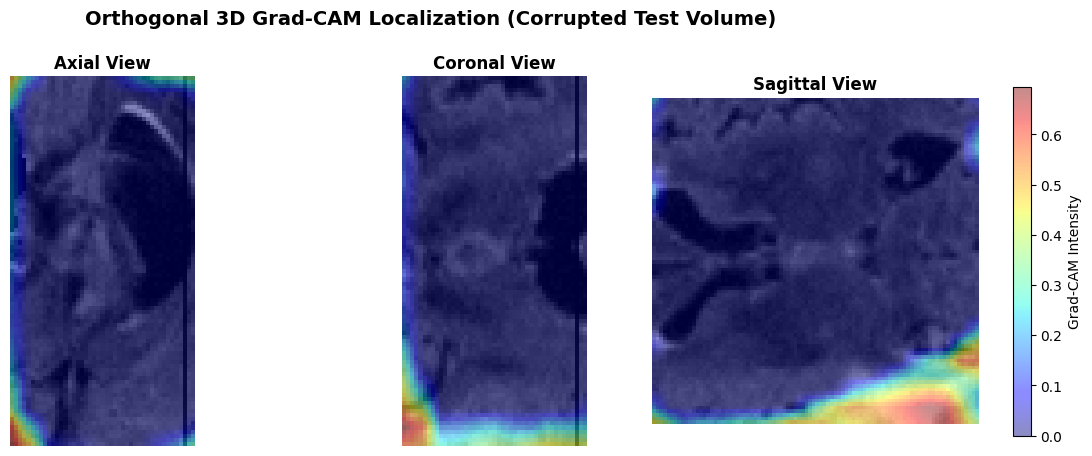

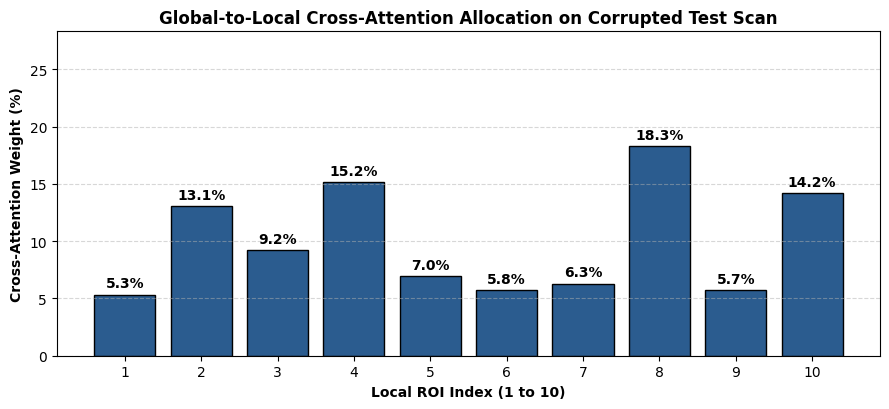

In [10]:
import matplotlib.pyplot as plt

single_gpu_model = unwrap_model(model_cross_attn).to(DEVICE)
single_gpu_model.eval()

activations, gradients = [], []

def forward_hook(module, inp, out):
    activations.append(out.detach())

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0].detach())

target_layer = single_gpu_model.encoder_global.layer3
hook_f = target_layer.register_forward_hook(forward_hook)
hook_b = target_layer.register_full_backward_hook(backward_hook)

target_small, target_center = None, None
for small_rois, center_roi, labels in test_loader:
    poor_idx = (labels == 0).nonzero(as_tuple=True)[0]
    if len(poor_idx) > 0:
        idx0 = poor_idx[0]
        target_small = small_rois[idx0:idx0 + 1].to(DEVICE)
        target_center = center_roi[idx0:idx0 + 1].to(DEVICE)
        break

target_center.requires_grad_(True)
single_gpu_model.zero_grad()

logits, attn_weights_sample = single_gpu_model(target_small, target_center)
logits[0, 0].backward()  # Class 0: Artifact / Corrupted

act = activations[0]
grad = gradients[0]
weights = torch.mean(grad, dim=(2, 3, 4), keepdim=True)
cam_3d = torch.relu(torch.sum(weights * act, dim=1)).squeeze().cpu().numpy()

cam_min, cam_max = cam_3d.min(), cam_3d.max()
cam_3d = (cam_3d - cam_min) / (cam_max - cam_min + 1e-8)

hook_f.remove()
hook_b.remove()

input_vol_np = target_center.squeeze().detach().cpu().numpy()
d_mid, h_mid, w_mid = [s // 2 for s in input_vol_np.shape]
zoom_3d = tuple(input_vol_np.shape[i] / cam_3d.shape[i] for i in range(3))
cam_3d_full = ndimage.zoom(cam_3d, zoom_3d, order=1)

# 3-Plane Orthogonal Grad-CAM Montage
views = [
    ("Axial View", input_vol_np[d_mid, :, :], cam_3d_full[d_mid, :, :]),
    ("Coronal View", input_vol_np[:, h_mid, :], cam_3d_full[:, h_mid, :]),
    ("Sagittal View", input_vol_np[:, :, w_mid], cam_3d_full[:, :, w_mid]),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (title, img_slice, cam_slice) in zip(axes, views):
    ax.imshow(img_slice, cmap="gray")
    im = ax.imshow(cam_slice, cmap="jet", alpha=0.45)
    ax.set_title(title, fontweight="bold")
    ax.axis("off")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.015, pad=0.03).set_label("Grad-CAM Intensity")
plt.suptitle("Orthogonal 3D Grad-CAM Localization (Corrupted Test Volume)", fontsize=14, fontweight="bold", y=1.02)
plt.savefig("/kaggle/working/orthogonal_gradcam_montage.png", dpi=300, bbox_inches="tight")
plt.show()

# Regional Cross-Attention Allocation
weights_np = attn_weights_sample.detach().squeeze().cpu().numpy()
if weights_np.ndim > 1:
    weights_np = weights_np.mean(axis=0)
plt.figure(figsize=(9, 4.2))
bars = plt.bar(range(1, 11), weights_np * 100.0, color="#2b5c8f", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%", padding=3, fontweight="bold")
plt.xlabel("Local ROI Index (1 to 10)", fontweight="bold")
plt.ylabel("Cross-Attention Weight (%)", fontweight="bold")
plt.title("Global-to-Local Cross-Attention Allocation on Corrupted Test Scan", fontweight="bold")
plt.xticks(range(1, 11))
plt.ylim(0, max(weights_np * 100.0) + 10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("/kaggle/working/attention_distribution.png", dpi=300)
plt.show()


## Step 10: Shortcut-Free Multi-Severity Stress-Test (`Mild / Moderate / Severe`) & 95% Bootstrap CI
Applies brain-masked artifacts of graded severity on the unseen test subjects—preserving exact zero backgrounds and matched baseline scanner noise so even `mild` scans cannot be solved by noise-floor cheating.


In [11]:
from sklearn.metrics import balanced_accuracy_score

seed_everything(SEED)


def generate_masked_severity_artifact(clean_vol, level="mild"):
    mask = clean_vol > 0
    vol = clean_vol.copy()
    if level == "mild":
        vol = LeakFreeArtifactGenerator.add_motion_blur_masked(vol, mask, sigma_range=(0.65, 0.95))
    elif level == "moderate":
        vol = LeakFreeArtifactGenerator.add_motion_blur_masked(vol, mask, sigma_range=(1.1, 1.5))
        vol = LeakFreeArtifactGenerator.add_nyquist_ghosting_masked(vol, mask, intensity_range=(0.14, 0.22))
    else:
        vol, _ = LeakFreeArtifactGenerator.make_poor_volume(vol, mask)
        return vol
    return normalize_brain_volume(vol, mask)


stress_records = []
good_test_rows = test_df[test_df["quality_label"] == 1].reset_index(drop=True)

for _, row in good_test_rows.iterrows():
    clean_vol = np.load(row["volume_path"])
    stress_records.append({"volume": clean_vol, "label": 1, "severity": "clean"})
    for sev in ["mild", "moderate", "severe"]:
        stress_records.append({
            "volume": generate_masked_severity_artifact(clean_vol, level=sev),
            "label": 0,
            "severity": sev,
        })


class InMemoryStressDataset(Dataset):
    def __init__(self, records, helper_ds):
        self.records = records
        self.helper = helper_ds

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        vol = rec["volume"]
        small_rois = self.helper._extract_local_rois(vol)
        center_roi = self.helper._extract_center_roi(vol)
        return (
            torch.from_numpy(small_rois).float().unsqueeze(1),
            torch.from_numpy(center_roi).float().unsqueeze(0),
            torch.tensor(rec["label"], dtype=torch.long),
            rec["severity"],
        )


stress_loader = DataLoader(
    InMemoryStressDataset(stress_records, DTIRoiDataset(test_df, is_train=False)),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

model_cnn1.eval()
model_cnn2.eval()
model_self_attn.eval()
model_cross_attn.eval()

y_true_st, severities_st = [], []
pred_base_st, pred_self_st, pred_cross_st, prob_cross_st = [], [], [], []

with torch.no_grad():
    for s_rois, c_roi, lbls, sevs in stress_loader:
        B, N, C, D, H, W = s_rois.shape
        s_flat = s_rois.view(B * N, C, D, H, W).to(DEVICE, non_blocking=True)
        c_dev = c_roi.to(DEVICE, non_blocking=True)
        s_dev = s_rois.to(DEVICE, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=USE_AMP):
            p_c = torch.argmax(model_cnn2(c_dev), dim=1)
            p_s = torch.argmax(model_cnn1(s_flat), dim=1).view(B, N)
            log_s, _ = model_self_attn(s_dev, c_dev)
            log_c, _ = model_cross_attn(s_dev, c_dev)

        for b in range(B):
            s_tot = (0.6 * p_c[b].item()) + (0.4 * np.sum(p_s[b].cpu().numpy()))
            pred_base_st.append(1 if s_tot >= 2.5 else 0)

        pred_self_st.extend(torch.argmax(log_s, dim=1).cpu().numpy())
        pred_cross_st.extend(torch.argmax(log_c, dim=1).cpu().numpy())
        prob_cross_st.extend(F.softmax(log_c.float(), dim=1)[:, 1].cpu().numpy())
        y_true_st.extend(lbls.numpy())
        severities_st.extend(sevs)

stress_summary = pd.DataFrame([
    {
        "Model": "Baseline Voting 1",
        "Balanced Acc": f"{balanced_accuracy_score(y_true_st, pred_base_st)*100:.2f}%",
        "Raw Acc": f"{accuracy_score(y_true_st, pred_base_st)*100:.2f}%",
        "F1": f"{f1_score(y_true_st, pred_base_st, zero_division=0):.4f}",
    },
    {
        "Model": "Variant A: Self-Attention",
        "Balanced Acc": f"{balanced_accuracy_score(y_true_st, pred_self_st)*100:.2f}%",
        "Raw Acc": f"{accuracy_score(y_true_st, pred_self_st)*100:.2f}%",
        "F1": f"{f1_score(y_true_st, pred_self_st, zero_division=0):.4f}",
    },
    {
        "Model": "Proposed Variant B: Cross-Attn",
        "Balanced Acc": f"{balanced_accuracy_score(y_true_st, pred_cross_st)*100:.2f}%",
        "Raw Acc": f"{accuracy_score(y_true_st, pred_cross_st)*100:.2f}%",
        "F1": f"{f1_score(y_true_st, pred_cross_st, zero_division=0):.4f}",
    },
])
print("--- Multi-Severity Stress-Test Results ---")
print(stress_summary.to_string(index=False))

sev_arr = np.array(severities_st)
pred_c_arr = np.array(pred_cross_st)
true_arr = np.array(y_true_st)
print("\n--- Proposed Variant B Accuracy by Severity ---")
for sev in ["clean", "mild", "moderate", "severe"]:
    m = sev_arr == sev
    print(f"  * {sev.capitalize():<10} (n={int(np.sum(m))}): {accuracy_score(true_arr[m], pred_c_arr[m])*100:.2f}%")

# 95% Bootstrap CI on Balanced Accuracy (1,000 resamples)
rng = np.random.RandomState(SEED)
boot_bal = []
for _ in range(1000):
    idx = rng.choice(len(true_arr), size=len(true_arr), replace=True)
    if len(np.unique(true_arr[idx])) == 2:
        boot_bal.append(balanced_accuracy_score(true_arr[idx], pred_c_arr[idx]) * 100.0)
ci_lo, ci_hi = np.percentile(boot_bal, [2.5, 97.5])
print(f"\nProposed Model Stress-Test Balanced Acc: {np.mean(boot_bal):.2f}% (95% CI: [{ci_lo:.2f}%, {ci_hi:.2f}%])")
print(f"Proposed Model Stress-Test ROC-AUC:      {roc_auc_score(true_arr, prob_cross_st):.4f}")


--- Multi-Severity Stress-Test Results ---
                         Model Balanced Acc Raw Acc     F1
             Baseline Voting 1       76.67%  68.33% 0.5957
     Variant A: Self-Attention       81.67%  75.83% 0.6588
Proposed Variant B: Cross-Attn       90.56%  89.17% 0.8116

--- Proposed Variant B Accuracy by Severity ---
  * Clean      (n=30): 93.33%
  * Mild       (n=30): 76.67%
  * Moderate   (n=30): 100.00%
  * Severe     (n=30): 86.67%

Proposed Model Stress-Test Balanced Acc: 90.57% (95% CI: [84.13%, 95.73%])
Proposed Model Stress-Test ROC-AUC:      0.9496


## Step 11: Master Benchmark Summary, Plots & Output Archive



================ LEAK-FREE BENCHMARK REPORT ================

                                         Method             Split       Accuracy F1-Score ROC-AUC
         Shortcut Audit (Linear Stats Baseline)  Subject-wise Val         55.00%        -  0.6233
                   Baseline Voting 1 (Dual-CNN)     Hold-out Test         88.33%   0.8889  0.9200
                   Baseline Voting 2 (Dual-CNN)     Hold-out Test         86.67%   0.8667       -
           Variant A: Dual-CNN + Self-Attention     Hold-out Test         88.33%   0.8889  0.9167
Proposed Variant B: 3D ResNet + Cross-Attention     Hold-out Test         90.00%   0.9032  0.9078
       Proposed Variant B (5-Fold Leak-Free CV) 5-Fold GroupKFold 84.67% ± 5.52%   0.8547  0.8996


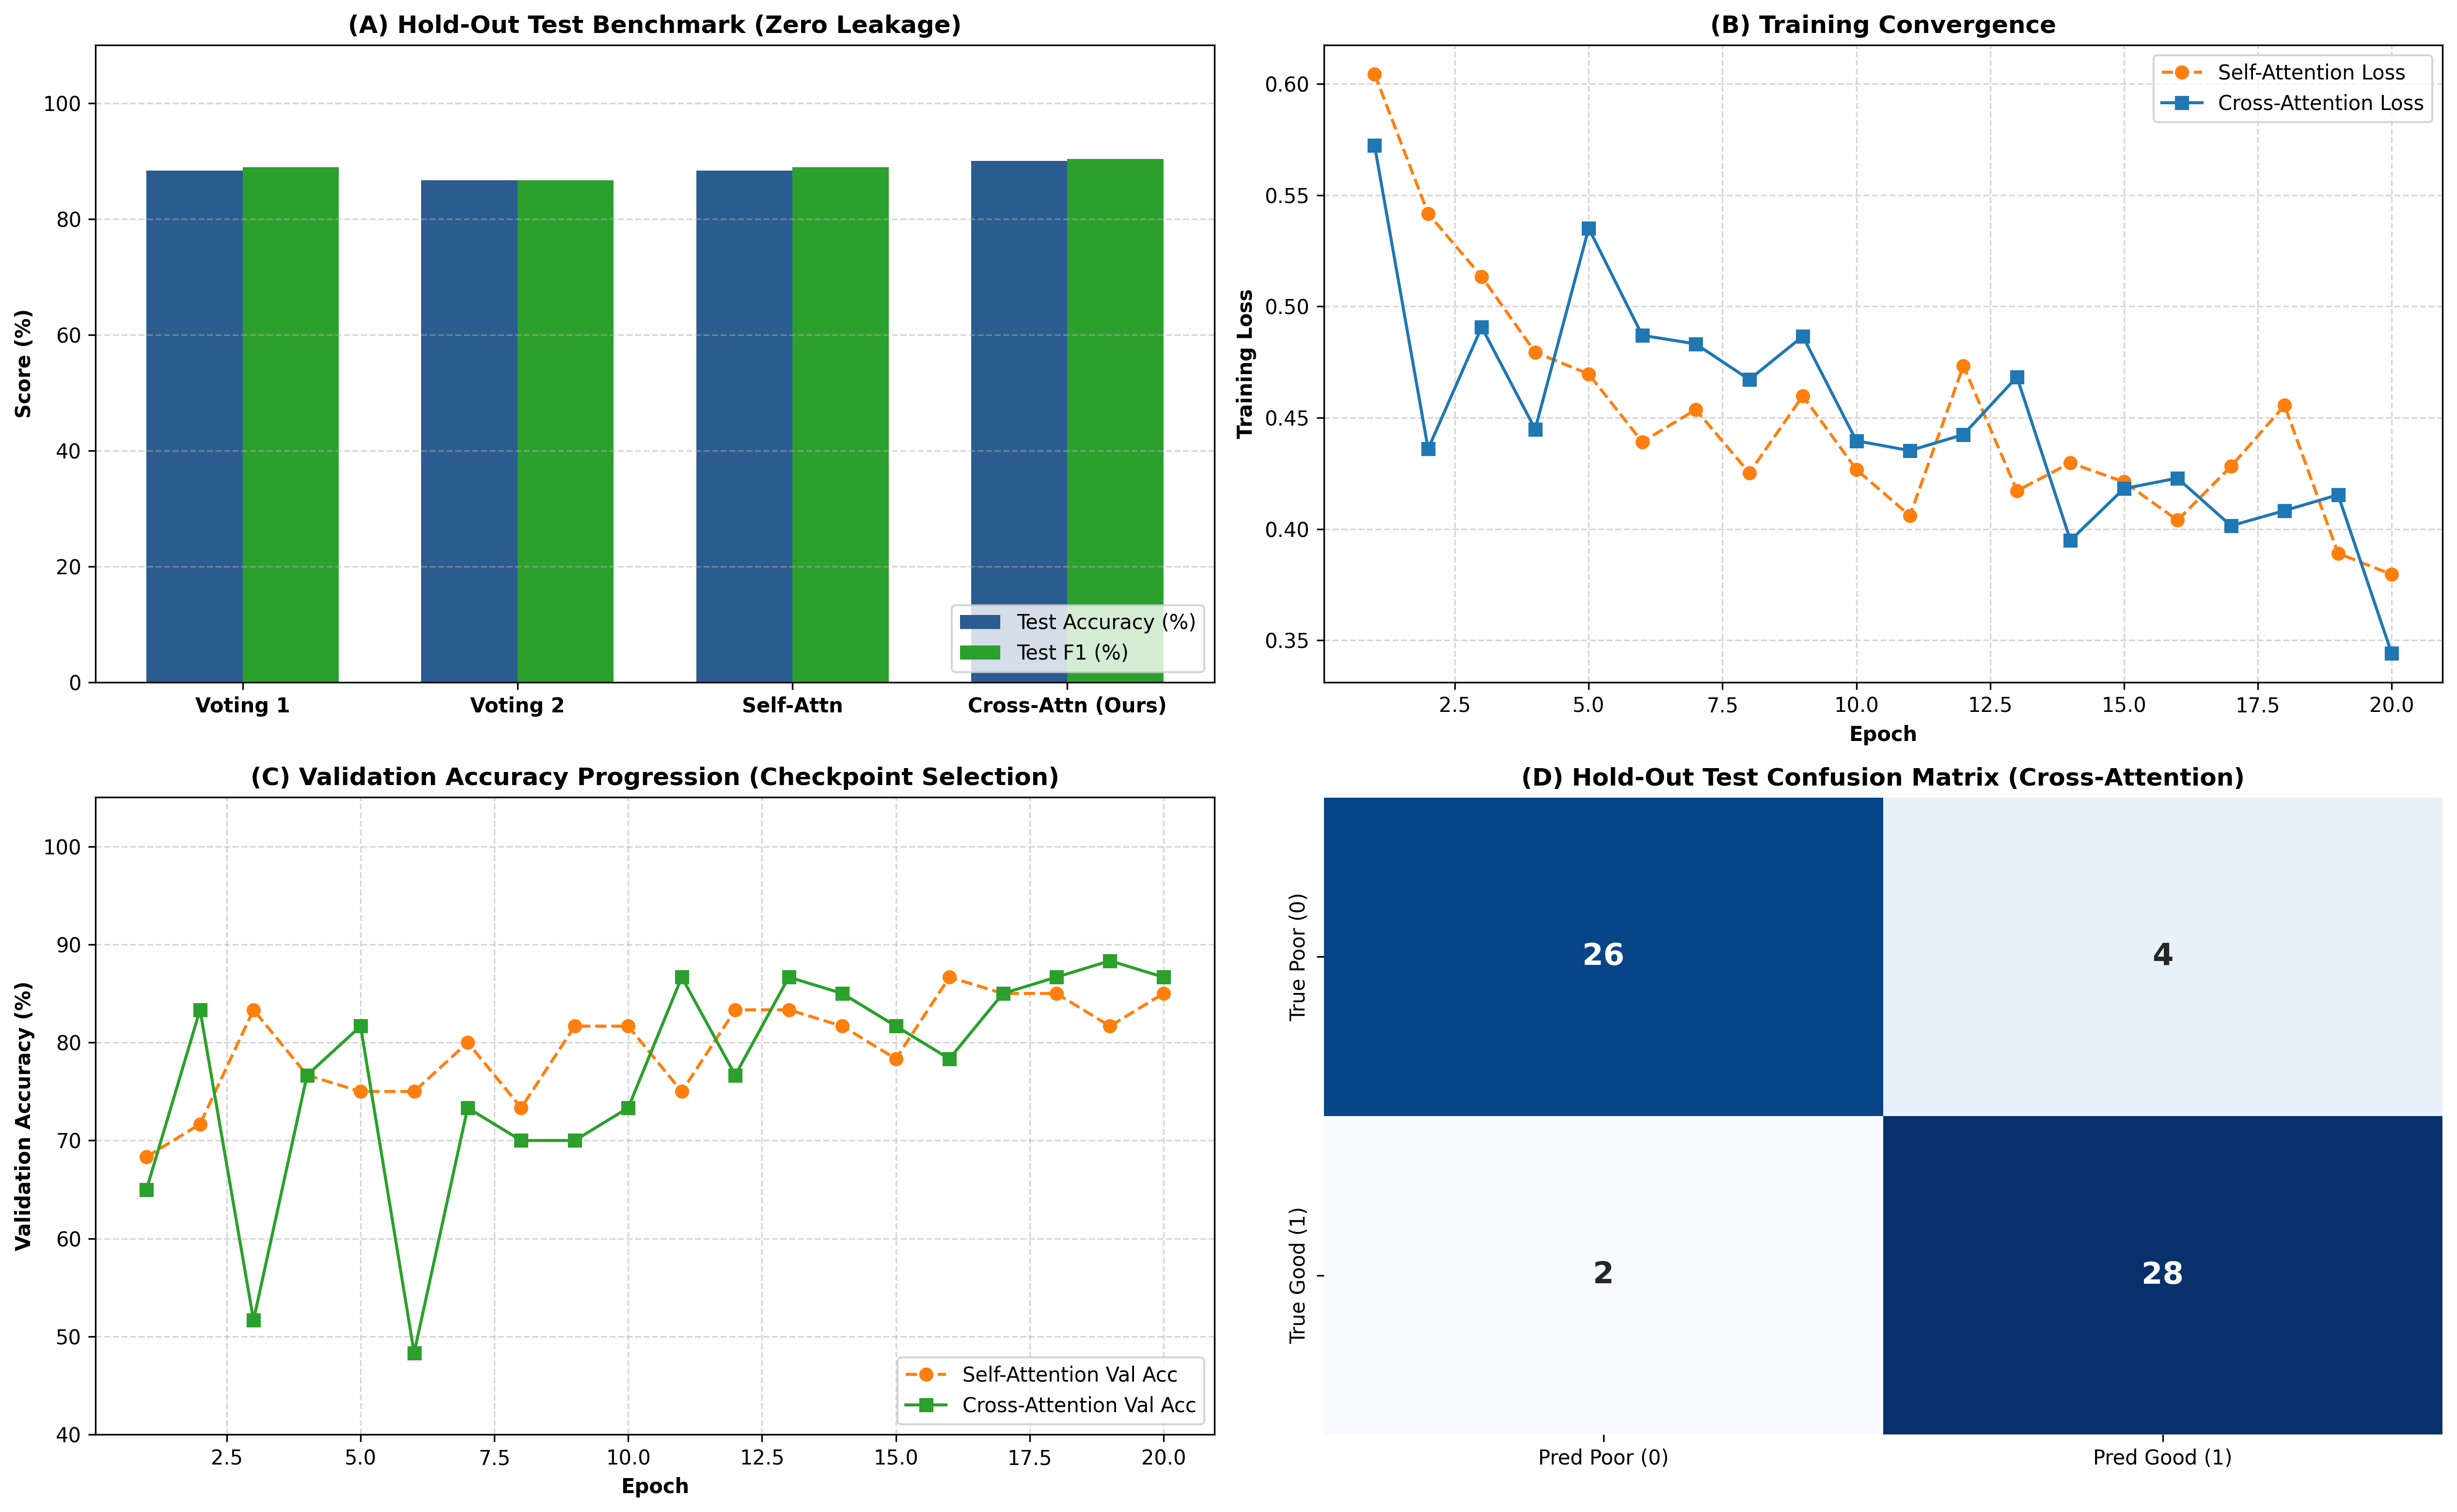

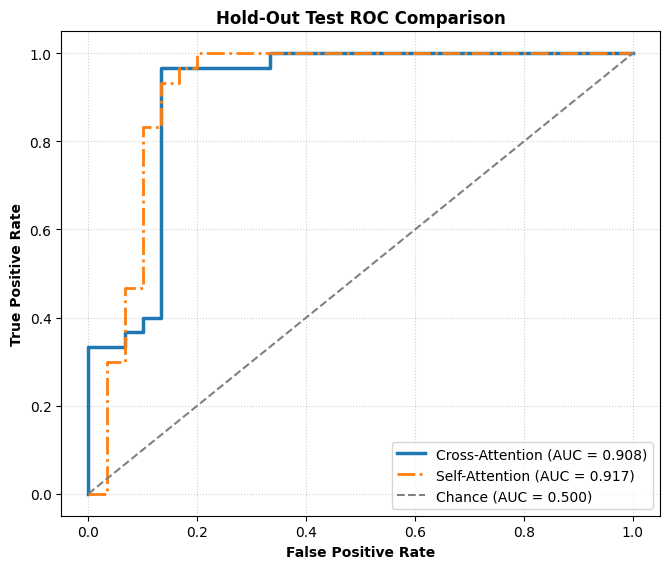

Archived outputs to: /kaggle/working/DTI_QC_LeakFree_2xT4_Outputs.zip


In [12]:
import shutil
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

results_summary = [
    {
        "Method": "Shortcut Audit (Linear Stats Baseline)",
        "Split": "Subject-wise Val",
        "Accuracy": f"{sc_acc:.2f}%",
        "F1-Score": "-",
        "ROC-AUC": f"{sc_auc:.4f}",
    },
    {
        "Method": "Baseline Voting 1 (Dual-CNN)",
        "Split": "Hold-out Test",
        "Accuracy": f"{acc_v1*100:.2f}%",
        "F1-Score": f"{f1_v1:.4f}",
        "ROC-AUC": f"{auc_v1:.4f}",
    },
    {
        "Method": "Baseline Voting 2 (Dual-CNN)",
        "Split": "Hold-out Test",
        "Accuracy": f"{acc_v2*100:.2f}%",
        "F1-Score": f"{f1_v2:.4f}",
        "ROC-AUC": "-",
    },
    {
        "Method": "Variant A: Dual-CNN + Self-Attention",
        "Split": "Hold-out Test",
        "Accuracy": f"{acc_s*100:.2f}%",
        "F1-Score": f"{f1_s:.4f}",
        "ROC-AUC": f"{auc_s:.4f}",
    },
    {
        "Method": "Proposed Variant B: 3D ResNet + Cross-Attention",
        "Split": "Hold-out Test",
        "Accuracy": f"{final_acc*100:.2f}%",
        "F1-Score": f"{final_f1:.4f}",
        "ROC-AUC": f"{final_auc:.4f}",
    },
    {
        "Method": "Proposed Variant B (5-Fold Leak-Free CV)",
        "Split": "5-Fold GroupKFold",
        "Accuracy": f"{np.mean(fold_accs):.2f}% ± {np.std(fold_accs):.2f}%",
        "F1-Score": f"{np.mean(fold_f1s):.4f}",
        "ROC-AUC": f"{np.mean(fold_aucs):.4f}",
    },
]

comparison_df = pd.DataFrame(results_summary)
comparison_df.to_csv("/kaggle/working/final_leakfree_benchmark.csv", index=False)
print("\n================ LEAK-FREE BENCHMARK REPORT ================\n")
print(comparison_df.to_string(index=False))

# 4-Panel Dashboard
fig = plt.figure(figsize=(17, 10.5), dpi=300)

ax1 = plt.subplot(2, 2, 1)
models_list = ["Voting 1", "Voting 2", "Self-Attn", "Cross-Attn (Ours)"]
acc_vals = [acc_v1 * 100, acc_v2 * 100, acc_s * 100, final_acc * 100]
f1_vals = [f1_v1 * 100, f1_v2 * 100, f1_s * 100, final_f1 * 100]
x = np.arange(len(models_list))
w = 0.35
ax1.bar(x - w / 2, acc_vals, w, label="Test Accuracy (%)", color="#2b5c8f")
ax1.bar(x + w / 2, f1_vals, w, label="Test F1 (%)", color="#2ca02c")
ax1.set_xticks(x)
ax1.set_xticklabels(models_list, fontweight="bold")
ax1.set_ylim(0, 110)
ax1.set_ylabel("Score (%)", fontweight="bold")
ax1.set_title("(A) Hold-Out Test Benchmark (Zero Leakage)", fontweight="bold")
ax1.legend(loc="lower right")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

ax2 = plt.subplot(2, 2, 2)
ep = np.arange(1, NUM_EPOCHS + 1)
ax2.plot(ep, loss_history_self, "o--", color="#ff7f0e", label="Self-Attention Loss")
ax2.plot(ep, loss_history_cross, "s-", color="#1f77b4", label="Cross-Attention Loss")
ax2.set_xlabel("Epoch", fontweight="bold")
ax2.set_ylabel("Training Loss", fontweight="bold")
ax2.set_title("(B) Training Convergence", fontweight="bold")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

ax3 = plt.subplot(2, 2, 3)
ax3.plot(ep, val_acc_history_self, "o--", color="#ff7f0e", label="Self-Attention Val Acc")
ax3.plot(ep, val_acc_history_cross, "s-", color="#2ca02c", label="Cross-Attention Val Acc")
ax3.set_xlabel("Epoch", fontweight="bold")
ax3.set_ylabel("Validation Accuracy (%)", fontweight="bold")
ax3.set_title("(C) Validation Accuracy Progression (Checkpoint Selection)", fontweight="bold")
ax3.set_ylim(40, 105)
ax3.legend(loc="lower right")
ax3.grid(True, linestyle="--", alpha=0.5)

ax4 = plt.subplot(2, 2, 4)
cm_final = confusion_matrix(y_true_final, y_pred_final)
sns.heatmap(
    cm_final, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax4,
    annot_kws={"size": 15, "weight": "bold"},
    xticklabels=["Pred Poor (0)", "Pred Good (1)"],
    yticklabels=["True Poor (0)", "True Good (1)"],
)
ax4.set_title("(D) Hold-Out Test Confusion Matrix (Cross-Attention)", fontweight="bold")

plt.tight_layout()
plt.savefig("/kaggle/working/dti_qc_leakfree_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

# ROC Curve Comparison
fpr_s, tpr_s, _ = roc_curve(y_true_self, y_probs_self)
fpr_c, tpr_c, _ = roc_curve(y_true_final, y_probs_final)
plt.figure(figsize=(6.8, 5.8))
plt.plot(fpr_c, tpr_c, color="#1f77b4", lw=2.5, label=f"Cross-Attention (AUC = {auc(fpr_c, tpr_c):.3f})")
plt.plot(fpr_s, tpr_s, color="#ff7f0e", lw=2.0, linestyle="-.", label=f"Self-Attention (AUC = {auc(fpr_s, tpr_s):.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Chance (AUC = 0.500)")
plt.xlabel("False Positive Rate", fontweight="bold")
plt.ylabel("True Positive Rate", fontweight="bold")
plt.title("Hold-Out Test ROC Comparison", fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("/kaggle/working/roc_curve_leakfree.png", dpi=300)
plt.show()

# Archive All Outputs
bundle_dir = "/kaggle/working/leakfree_outputs_bundle"
os.makedirs(bundle_dir, exist_ok=True)
for src in [
    "/kaggle/working/dti_qc_leakfree_dashboard.png",
    "/kaggle/working/orthogonal_gradcam_montage.png",
    "/kaggle/working/attention_distribution.png",
    "/kaggle/working/roc_curve_leakfree.png",
    "/kaggle/working/final_leakfree_benchmark.csv",
    "/kaggle/working/train_metadata.csv",
    "/kaggle/working/val_metadata.csv",
    "/kaggle/working/test_metadata.csv",
    best_self_attn_path,
    best_cross_attn_path,
]:
    if os.path.exists(src):
        shutil.copy(src, bundle_dir)

archive_path = "/kaggle/working/DTI_QC_LeakFree_2xT4_Outputs"
shutil.make_archive(archive_path, "zip", bundle_dir)
print(f"Archived outputs to: {archive_path}.zip")
